## NB07 — Análise Exploratória de Dados (EDA)

**Entrada:** `data/processed/dataset_ml_clean.csv` — 74.755 linhas × 28 colunas, 0 NaN (gerado pelo NB06)

**Objetivo:** Compreender a estrutura, distribuições, padrões e anomalias do dataset antes de aplicar os modelos
de detecção de anomalias (Isolation Forest, LOF, One-Class SVM no NB08).
A EDA responde perguntas concretas:
- Qual é o perfil de preço das propostas? Onde estão os desvios mais extremos?
- O volume de licitações varia ao longo do tempo? Existe sazonalidade por mês ou trimestre?
- O ciclo eleitoral se reflete nos dados? Há mais contratações em períodos pré-eleitorais?
- Fornecedores de fora de PE dominam determinadas modalidades ou órgãos?
- Quais modalidades concentram maior risco de anomalia pelo perfil das propostas?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
from scipy import stats

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120

print('Setup OK')

Setup OK


In [2]:
import os
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

os.makedirs('figuras_tcc', exist_ok=True)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.dpi'] = 200
plt.rcParams['axes.unicode_minus'] = True

def br(x, casas=0):
    """12345.678 -> '12.345,7' (ponto no milhar, vírgula decimal, sinal de menos correto)."""
    s = f'{round(x, casas) + 0.0:,.{casas}f}'  # '+ 0.0' evita '-0,00'
    return s.replace(',', '#').replace('.', ',').replace('#', '.').replace('-', '\u2212')

def fmt_eixo(ax, eixo='y', casas=0, pct=False):
    """Formato brasileiro nos números de um eixo. pct=True: multiplica por 100 e acrescenta '%'."""
    if pct:
        f = FuncFormatter(lambda v, _: br(v * 100, casas) + '%')
    else:
        f = FuncFormatter(lambda v, _: br(v, casas))
    (ax.yaxis if eixo == 'y' else ax.xaxis).set_major_formatter(f)

---
### 1. Carregamento e Visão Geral

In [3]:
df = pd.read_csv('data/processed/dataset_ml_clean.csv')

print(f'Shape: {df.shape}')
print(f'\nColunas ({len(df.columns)}):')
print(list(df.columns))
print('\nTipos de dados:')
print(df.dtypes)
print(f'\nValores ausentes: {df.isnull().sum().sum()} (esperado: 0)')

df.head()

Shape: (74755, 28)

Colunas (28):
['orgaoEntidadeCnpj', 'anoCompraPncp', 'sequencialCompraPncp', 'numeroItem', 'cnpj_forn_norm', 'desvio_item_estimado', 'n_propostas_item', 'fornecedor_unico', 'ano', 'mes', 'trimestre', 'dia_semana', 'dias_desde_eleicao', 'pre_eleitoral_180d', 'pos_eleitoral_180d', 'fornecedor_fora_pe', 'tipo_fornecedor', 'idade_empresa_anos', 'empresa_nova', 'opcao_pelo_mei', 'opcao_pelo_simples', 'modalidadeNome', 'porte', 'cnae_fiscal', 'descricao_situacao_cadastral', 'modalidade_Dispensa', 'modalidade_Inexigibilidade', 'modalidade_Licitacao']

Tipos de dados:
orgaoEntidadeCnpj                 int64
anoCompraPncp                     int64
sequencialCompraPncp              int64
numeroItem                        int64
cnpj_forn_norm                    int64
desvio_item_estimado            float64
n_propostas_item                  int64
fornecedor_unico                  int64
ano                               int64
mes                               int64
trimestre    

,orgaoEntidadeCnpj,anoCompraPncp,sequencialCompraPncp,numeroItem,cnpj_forn_norm,desvio_item_estimado,n_propostas_item,fornecedor_unico,ano,mes,...,empresa_nova,opcao_pelo_mei,opcao_pelo_simples,modalidadeNome,porte,cnae_fiscal,descricao_situacao_cadastral,modalidade_Dispensa,modalidade_Inexigibilidade,modalidade_Licitacao
0,2030715000112,2023,1,1,44051659000142,-0.354518,1,1,2023,1,...,0,0,0,Dispensa,0,-1,0,1,0,0
1,2030715000112,2023,3,1,44051659000142,-0.019704,1,1,2023,1,...,0,0,0,Dispensa,0,-1,0,1,0,0
2,508903000188,2022,324,1,32212672000157,0.000000,1,1,2023,1,...,0,0,0,Dispensa,0,-1,0,1,0,0
3,2030715000112,2023,2,1,46941329000158,-0.006719,1,1,2023,1,...,0,0,0,Dispensa,0,-1,0,1,0,0
4,15126437000143,2022,846,1,2515391000374,0.000000,1,1,2023,1,...,0,0,0,Pregão - Eletrônico,0,-1,0,0,0,1


In [4]:
df.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
orgaoEntidadeCnpj,74755.0,7.870019e+12,8.873015e+12,3.816600e+10,3.480030e+11,3.944290e+11,3.944520e+11,7.868234e+12,1.135814e+13,2.698972e+13,3.587281e+13,4.235748e+13
anoCompraPncp,74755.0,2.023684e+03,4.743770e-01,2.022000e+03,2.023000e+03,2.023000e+03,2.023000e+03,2.024000e+03,2.024000e+03,2.024000e+03,2.024000e+03,2.025000e+03
sequencialCompraPncp,74755.0,3.737936e+03,5.657277e+03,1.000000e+00,1.000000e+00,6.000000e+00,6.950000e+01,5.900000e+02,4.243000e+03,1.560000e+04,2.123600e+04,2.256900e+04
numeroItem,74755.0,5.859122e+01,8.479785e+01,1.000000e+00,1.000000e+00,1.000000e+00,5.000000e+00,2.500000e+01,7.400000e+01,2.450000e+02,4.160000e+02,5.030000e+02
cnpj_forn_norm,74755.0,2.656627e+13,2.042288e+14,0.000000e+00,2.798058e+09,1.055361e+10,8.852775e+12,2.417406e+13,4.126394e+13,5.356800e+13,7.147480e+13,5.562232e+16
desvio_item_estimado,74755.0,-2.300861e-01,5.377955e-01,-1.000000e+00,-8.661920e-01,-7.034271e-01,-4.084191e-01,-1.666667e-01,0.000000e+00,0.000000e+00,0.000000e+00,9.275000e+01
n_propostas_item,74755.0,1.245642e+00,2.025040e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00,4.000000e+00,4.200000e+01
fornecedor_unico,74755.0,9.159655e-01,2.774414e-01,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
ano,74755.0,2.023722e+03,4.481496e-01,2.023000e+03,2.023000e+03,2.023000e+03,2.023000e+03,2.024000e+03,2.024000e+03,2.024000e+03,2.024000e+03,2.024000e+03
mes,74755.0,7.449027e+00,3.109416e+00,1.000000e+00,1.000000e+00,2.000000e+00,5.000000e+00,8.000000e+00,1.000000e+01,1.200000e+01,1.200000e+01,1.200000e+01


---
### 2. Visão Geral: Cardinalidades e Entidades

- **orgaoEntidadeCnpj**: número de órgãos compradores distintos no dataset
- **cnpj_forn_norm**: número de fornecedores únicos
- **modalidadeNome**: número de modalidades licitatórias presentes
- **cnae_fiscal**: diversidade de setores econômicos dos fornecedores

In [5]:
cardinalidade = pd.DataFrame({
    'unicos': df.nunique(),
    'pct_total': (df.nunique() / len(df) * 100).round(2)
}).sort_values('unicos', ascending=False)

print('Cardinalidade por coluna:')
print(cardinalidade.to_string())

print('\n--- Resumo de entidades ---')
n_orgaos = df['orgaoEntidadeCnpj'].nunique()
n_forn   = df['cnpj_forn_norm'].nunique()
n_contr  = df.groupby(['orgaoEntidadeCnpj','anoCompraPncp','sequencialCompraPncp']).ngroups
print(f'Orgaos compradores:  {n_orgaos:>6,}')
print(f'Fornecedores unicos: {n_forn:>6,}')
print(f'Contratacoes:        {n_contr:>6,}')
print(f'Propostas (linhas):  {len(df):>6,}')

Cardinalidade por coluna:
                              unicos  pct_total
desvio_item_estimado           43708      58.47
cnpj_forn_norm                  9437      12.62
idade_empresa_anos              7382       9.87
sequencialCompraPncp            4156       5.56
dias_desde_eleicao               520       0.70
cnae_fiscal                      512       0.68
numeroItem                       503       0.67
orgaoEntidadeCnpj                103       0.14
n_propostas_item                  21       0.03
mes                               12       0.02
dia_semana                         7       0.01
modalidadeNome                     6       0.01
trimestre                          4       0.01
descricao_situacao_cadastral       4       0.01
anoCompraPncp                      4       0.01
porte                              4       0.01
opcao_pelo_simples                 2       0.00
modalidade_Dispensa                2       0.00
modalidade_Inexigibilidade         2       0.00
pos_eleitoral_

---
### 3. Distribuições das Features Numéricas Contínuas

- **`desvio_item_estimado`**: desvio percentual do preço vencedor em relação ao teto unitário
  estimado no edital. Valor 0 = cobrou exatamente o estimado; valor 1 = 100% acima (sobrepreço);
  −1 = 100% abaixo (desconto). Sobrepreços extremos são candidatos diretos a anomalia.
- **`idade_empresa_anos`**: idade da empresa na data da proposta. Empresas muito novas em
  contratações de alto valor são sinal clássico de risco.
- **`dias_desde_eleicao`**: distância em dias, com sinal, até a eleição municipal de 06/10/2024 (negativa antes, positiva depois).

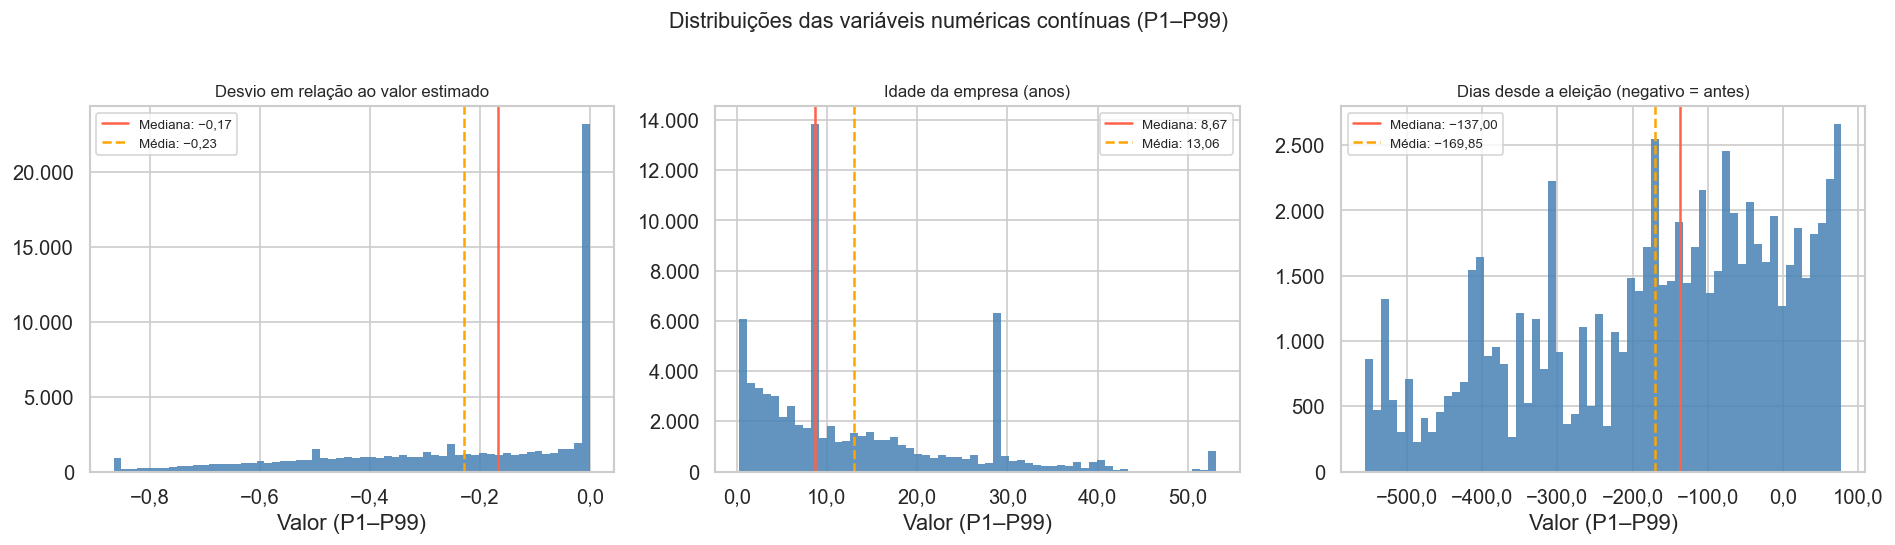

,desvio_item_estimado,idade_empresa_anos,dias_desde_eleicao
count,74755.000,74755.000,74755.000
mean,-0.230,13.056,-169.849
std,0.538,11.417,173.107
min,-1.000,0.000,-641.000
1%,-0.866,0.285,-556.000
5%,-0.703,0.780,-500.000
25%,-0.408,4.533,-305.000
50%,-0.167,8.671,-137.000
75%,0.000,18.582,-31.000
95%,0.000,33.764,60.000


In [6]:
numericas = ['desvio_item_estimado', 'idade_empresa_anos', 'dias_desde_eleicao']
titulos_numericas = {
    'desvio_item_estimado': 'Desvio em relação ao valor estimado',
    'idade_empresa_anos': 'Idade da empresa (anos)',
    'dias_desde_eleicao': 'Dias desde a eleição (negativo = antes)',
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for i, col in enumerate(numericas):
    data = df[col].dropna()
    p1, p99 = data.quantile(0.01), data.quantile(0.99)
    data_vis = data.clip(p1, p99)
    axes[i].hist(data_vis, bins=60, color='steelblue', edgecolor='none', alpha=0.85)
    med_val = data.median()
    mean_val = data.mean()
    axes[i].axvline(med_val, color='tomato', linewidth=1.5, label=f'Mediana: {br(med_val, 2)}')
    axes[i].axvline(mean_val, color='orange', linewidth=1.5, linestyle='--', label=f'Média: {br(mean_val, 2)}')
    axes[i].set_title(titulos_numericas[col], fontsize=10)
    axes[i].set_xlabel('Valor (P1–P99)')
    axes[i].legend(fontsize=8)
    fmt_eixo(axes[i], 'x', 1)
    fmt_eixo(axes[i], 'y', 0)

plt.suptitle('Distribuições das variáveis numéricas contínuas (P1–P99)', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('figuras_tcc/image16.png', dpi=200, bbox_inches='tight')
plt.show()

df[numericas].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).round(3)

---
### 4. Distribuições das Features Categóricas e Binárias

- **`fornecedor_unico`**: 1 se apenas um vencedor registrado no item (91,6%). Desequilíbrio
  parcialmente artefato da API PNCP (retorna só vencedor).
- **`fornecedor_fora_pe`**: 1 se fornecedor é de outro estado (62,8%).
- **`tipo_fornecedor`**: 1 = pessoa jurídica (91,9%), 0 = pessoa física (8,1%).
- **`empresa_nova`**: 1 se empresa com < 1 ano de existência na data da proposta.
- **`porte`**: ordinal — 0=desconhecido, 1=micro, 2=EPP, 3=demais.
- **`modalidadeNome`**: modalidade licitatória, com o nome original (na EDA). Nos modelos entra como
  one-hot em 3 grupos (`modalidade_Licitacao`, `modalidade_Dispensa`, `modalidade_Inexigibilidade`, NB06).
- **`descricao_situacao_cadastral`**: ordinal — 0=ativa ou sem cadastro, 1=suspensa, 2=inapta, 3=baixada.

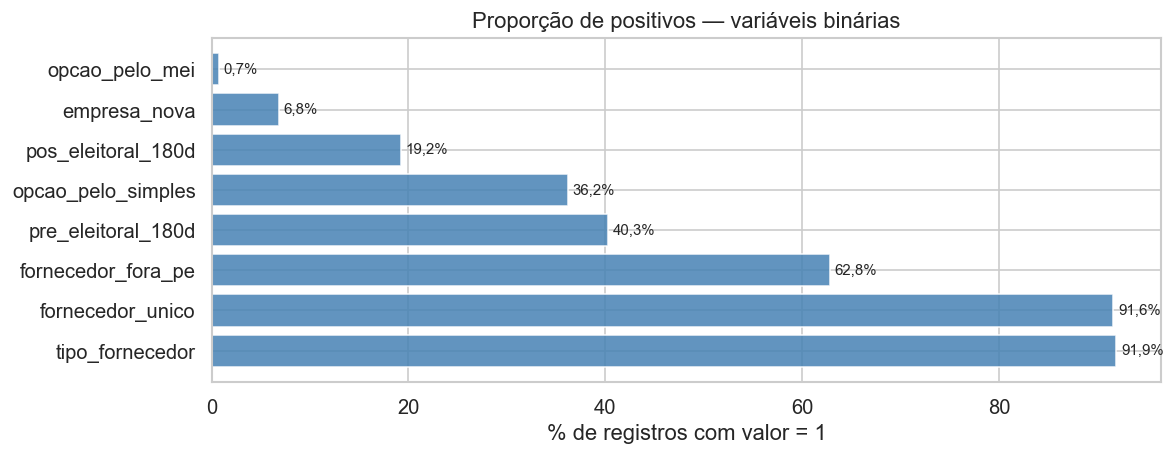

In [7]:
binarias = ['fornecedor_unico', 'fornecedor_fora_pe', 'tipo_fornecedor',
            'empresa_nova', 'pre_eleitoral_180d', 'pos_eleitoral_180d',
            'opcao_pelo_mei', 'opcao_pelo_simples']

prop = df[binarias].mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.barh(prop.index, prop.values * 100, color='steelblue', alpha=0.85)
ax.set_xlabel('% de registros com valor = 1')
ax.set_title('Proporção de positivos — variáveis binárias')
for bar, val in zip(bars, prop.values):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
            f'{br(val*100, 1)}%', va='center', fontsize=9)
fmt_eixo(ax, 'x', 0)
plt.tight_layout()
plt.show()

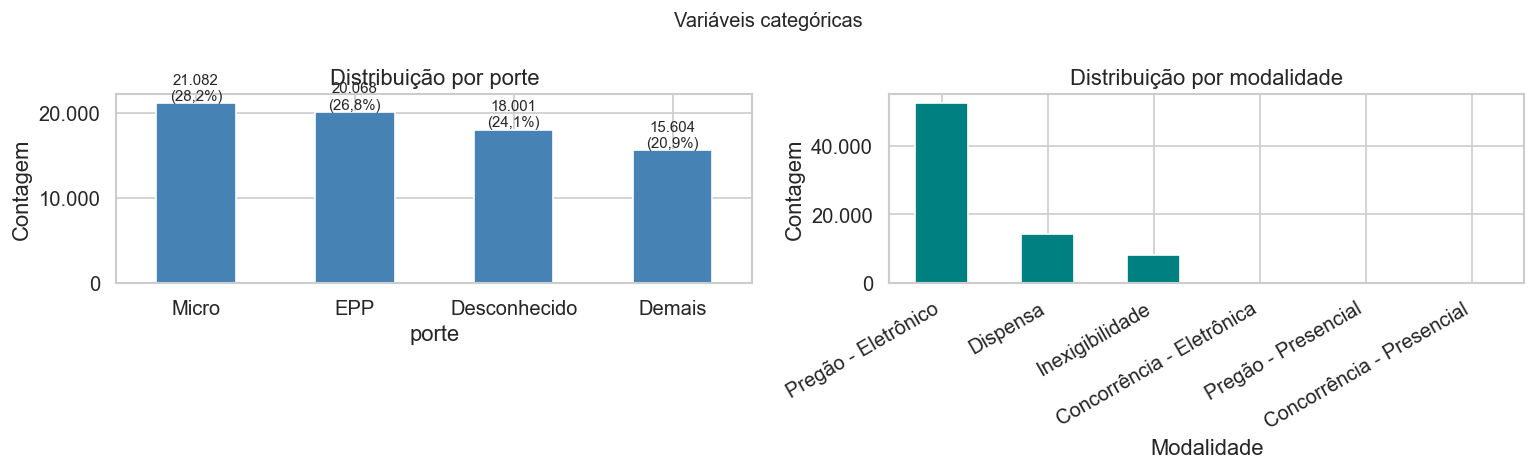

In [8]:
porte_labels = {0: 'Desconhecido', 1: 'Micro', 2: 'EPP', 3: 'Demais'}
porte_counts = df['porte'].map(porte_labels).value_counts()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

porte_counts.plot(kind='bar', ax=axes[0], color='steelblue', rot=0)
axes[0].set_title('Distribuição por porte')
axes[0].set_ylabel('Contagem')
for p in axes[0].patches:
    pct = p.get_height() / len(df) * 100
    axes[0].annotate(f'{br(p.get_height(), 0)}\n({br(pct, 1)}%)',
                     (p.get_x() + p.get_width()/2, p.get_height()),
                     ha='center', va='bottom', fontsize=9)
fmt_eixo(axes[0], 'y', 0)

df['modalidadeNome'].value_counts().plot(kind='bar', ax=axes[1], color='teal', rot=30)
plt.setp(axes[1].get_xticklabels(), ha='right')
axes[1].set_title('Distribuição por modalidade')
axes[1].set_xlabel('Modalidade')
axes[1].set_ylabel('Contagem')
fmt_eixo(axes[1], 'y', 0)

plt.suptitle('Variáveis categóricas', fontsize=12)
plt.tight_layout()
plt.show()

---
### 5. Análise de Outliers de Preço

Sobrepreços e subpreços extremos:

1. **Thresholds de sobrepreço**: proporção de propostas com `desvio_item_estimado` > 0.5
   (50% acima do teto estimado), > 1.0 (dobro do estimado), > 2.0 (triplo).
2. **Top 20 outliers**: propostas com os maiores desvios para inspeção manual.
3. **Perfil dos outliers**: distribuição por porte, tipo de fornecedor e perfil de empresa
   — sinaliza quais combinações concentram maior risco.

In [9]:
thresholds_desvio = [0.1, 0.5, 1.0, 2.0, 5.0, 10.0]

print('=== desvio_item_estimado ===')
for t in thresholds_desvio:
    n = (df['desvio_item_estimado'] > t).sum()
    pct = n / len(df) * 100
    print(f'  > {t}: {n:>8,} propostas ({pct:.2f}%)')

=== desvio_item_estimado ===
  > 0.1:      107 propostas (0.14%)
  > 0.5:       44 propostas (0.06%)
  > 1.0:       25 propostas (0.03%)
  > 2.0:       14 propostas (0.02%)
  > 5.0:        6 propostas (0.01%)
  > 10.0:        3 propostas (0.00%)


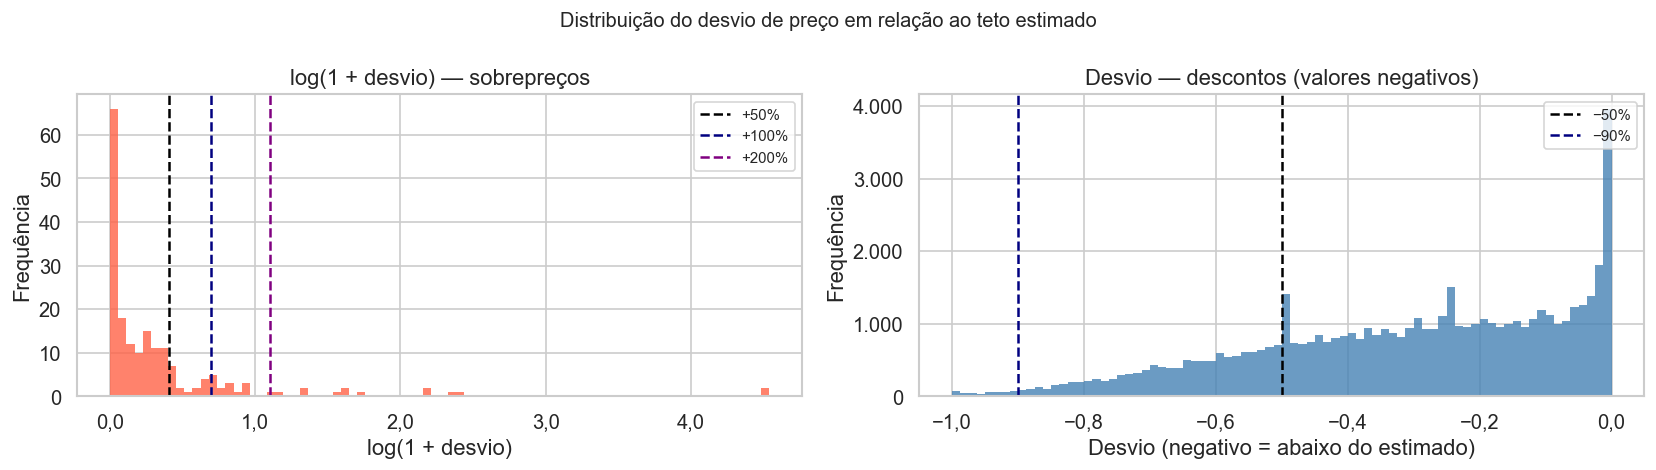

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sobrepreco = df.loc[df['desvio_item_estimado'] > 0, 'desvio_item_estimado']
axes[0].hist(np.log1p(sobrepreco), bins=80, color='tomato', alpha=0.8, edgecolor='none')
axes[0].set_title('log(1 + desvio) — sobrepreços')
axes[0].set_xlabel('log(1 + desvio)')
axes[0].set_ylabel('Frequência')
axes[0].axvline(np.log1p(0.5), color='black', linestyle='--', label='+50%')
axes[0].axvline(np.log1p(1.0), color='navy', linestyle='--', label='+100%')
axes[0].axvline(np.log1p(2.0), color='purple', linestyle='--', label='+200%')
axes[0].legend(fontsize=9)
fmt_eixo(axes[0], 'x', 1)
fmt_eixo(axes[0], 'y', 0)

desconto = df.loc[df['desvio_item_estimado'] < 0, 'desvio_item_estimado']
axes[1].hist(desconto, bins=80, color='steelblue', alpha=0.8, edgecolor='none')
axes[1].set_title('Desvio — descontos (valores negativos)')
axes[1].set_xlabel('Desvio (negativo = abaixo do estimado)')
axes[1].set_ylabel('Frequência')
axes[1].axvline(-0.5, color='black', linestyle='--', label='\u221250%')
axes[1].axvline(-0.9, color='navy', linestyle='--', label='\u221290%')
axes[1].legend(fontsize=9)
fmt_eixo(axes[1], 'x', 1)
fmt_eixo(axes[1], 'y', 0)

plt.suptitle('Distribuição do desvio de preço em relação ao teto estimado', fontsize=12)
plt.tight_layout()
plt.savefig('figuras_tcc/image3.png', dpi=200, bbox_inches='tight')
plt.show()

In [11]:
# Top 20 outliers de sobrepreco
cols_top = ['orgaoEntidadeCnpj','anoCompraPncp','sequencialCompraPncp','numeroItem',
            'cnpj_forn_norm','desvio_item_estimado',
            'porte','tipo_fornecedor','empresa_nova']
outliers_preco = df.nlargest(20, 'desvio_item_estimado')[cols_top]
print('Top 20 propostas com maior sobrepreco:')
outliers_preco

Top 20 propostas com maior sobrepreco:


,orgaoEntidadeCnpj,anoCompraPncp,sequencialCompraPncp,numeroItem,cnpj_forn_norm,desvio_item_estimado,porte,tipo_fornecedor,empresa_nova
16629,394452000103,2023,9953,95,7199135000177,92.750000,2,1,0
16621,394452000103,2023,9953,73,29868059000188,89.476190,3,1,0
31147,394502000144,2024,2623,2,52934421000193,10.473684,1,1,1
64937,26474056000171,2024,308,6,31978612000187,9.500000,0,1,0
44959,11674751000100,2024,5,19,13531477000145,8.083333,1,1,0
14345,394452000103,2023,12887,43,207275000109,8.065657,2,1,0
42892,394460000141,2024,857,1,23186928000108,4.787606,1,1,0
42172,11674777000158,2024,21,1,19703791000144,3.993037,3,1,0
14312,394452000103,2023,12887,10,207275000109,3.961538,2,1,0
14309,394452000103,2023,12887,7,207275000109,3.781250,2,1,0


Propostas com desvio > 100%: 25 (0.0%)


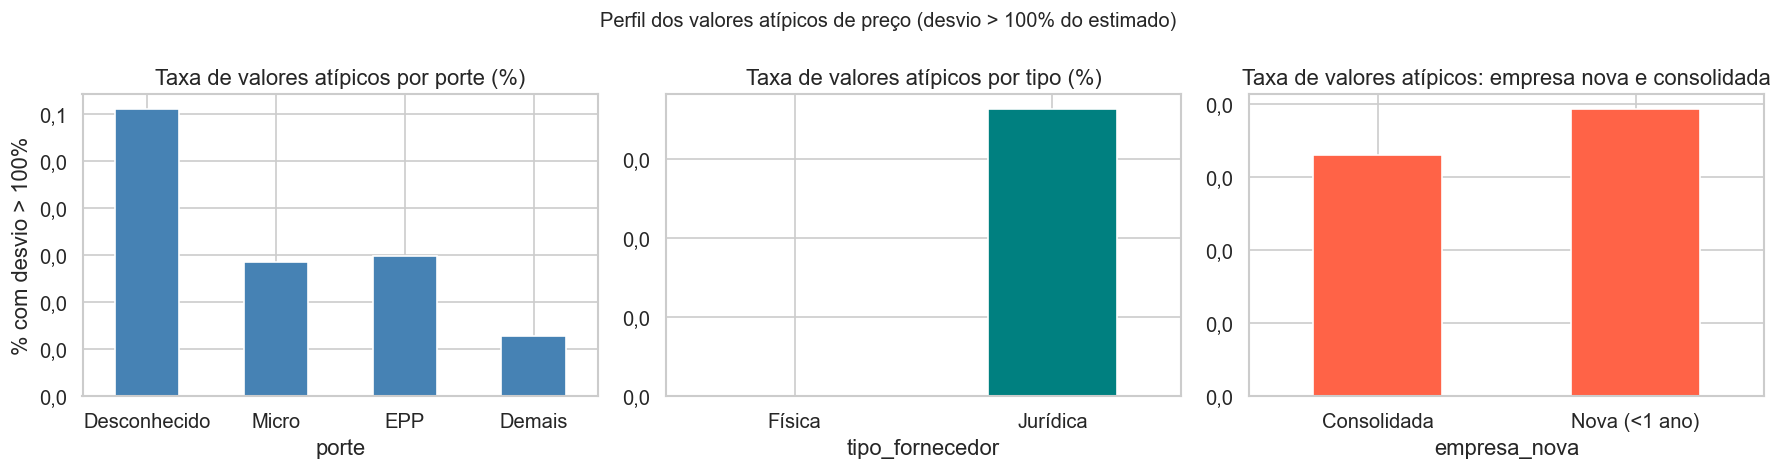

In [12]:
# Perfil dos outliers
df['outlier_preco'] = (df['desvio_item_estimado'] > 1.0).astype(int)
n_outliers = df['outlier_preco'].sum()
pct_outliers = df['outlier_preco'].mean() * 100
print(f'Propostas com desvio > 100%: {n_outliers:,} ({pct_outliers:.1f}%)')

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

porte_map = {0: 'Desconhecido', 1: 'Micro', 2: 'EPP', 3: 'Demais'}
taxa_porte = df.groupby('porte')['outlier_preco'].mean() * 100
taxa_porte.index = taxa_porte.index.map(porte_map)
taxa_porte.plot(kind='bar', ax=axes[0], color='steelblue', rot=0)
axes[0].set_title('Taxa de valores atípicos por porte (%)')
axes[0].set_ylabel('% com desvio > 100%')
fmt_eixo(axes[0], 'y', 1)

taxa_tipo = df.groupby('tipo_fornecedor')['outlier_preco'].mean() * 100
taxa_tipo.index = taxa_tipo.index.map({0: 'Física', 1: 'Jurídica'})
taxa_tipo.plot(kind='bar', ax=axes[1], color='teal', rot=0)
axes[1].set_title('Taxa de valores atípicos por tipo (%)')
fmt_eixo(axes[1], 'y', 1)

taxa_nova = df.groupby('empresa_nova')['outlier_preco'].mean() * 100
taxa_nova.index = taxa_nova.index.map({0: 'Consolidada', 1: 'Nova (<1 ano)'})
taxa_nova.plot(kind='bar', ax=axes[2], color='tomato', rot=0)
axes[2].set_title('Taxa de valores atípicos: empresa nova e consolidada')
fmt_eixo(axes[2], 'y', 1)

plt.suptitle('Perfil dos valores atípicos de preço (desvio > 100% do estimado)', fontsize=12)
plt.tight_layout()
plt.show()

---
### 6. Sazonalidade Temporal

1. **Ciclo orçamentário**: órgãos públicos tendem a concentrar contratações no final do ano
   (novembro–dezembro) para executar o orçamento aprovado, e no início (fevereiro–março)
   após a aprovação do PPA/LOA.
2. **Ciclo eleitoral**: 2024 é ano eleitoral municipal — esperamos pico de contratações
   no período pré-eleitoral (jan–out/2024).
3. **Efeito dia da semana**: contratações publicadas na sexta-feira têm menor visibilidade
   pública, o que pode facilitar irregularidades.
4. **Transição legal**: aumento acentuado de contratações entre 2023 e 2024 reflete
   a adesão crescente ao novo regime jurídico.

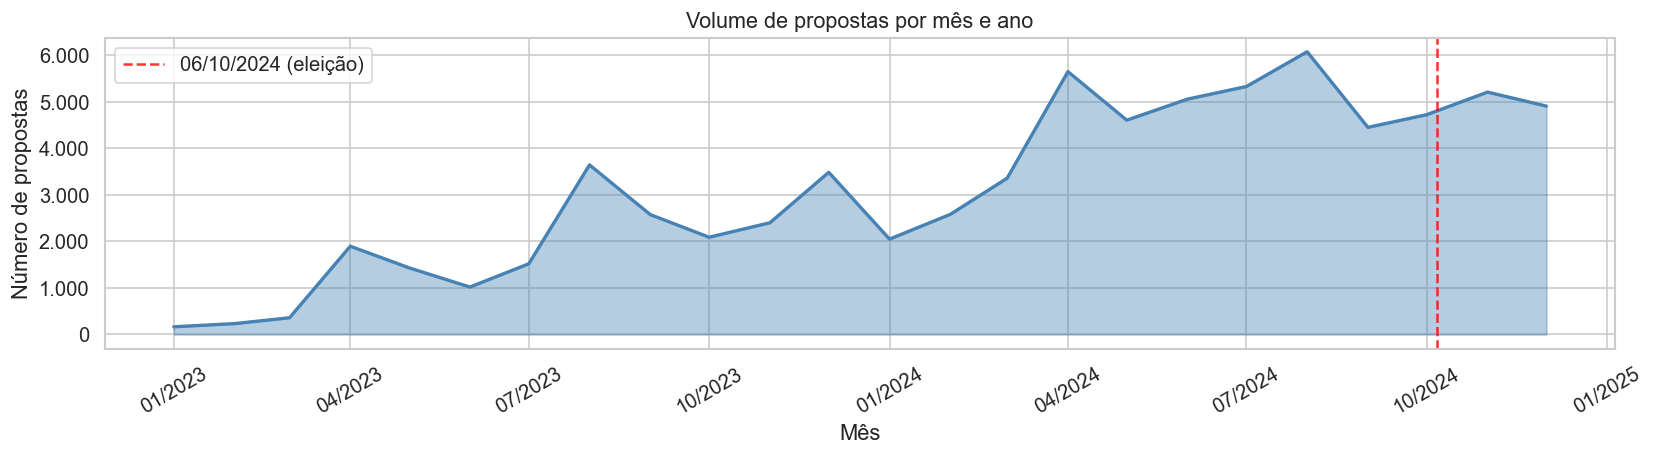

In [13]:
# Série temporal mensal
import matplotlib.dates as mdates
df['ano_mes'] = pd.to_datetime(df['ano'].astype(str) + '-' + df['mes'].astype(str).str.zfill(2) + '-01')
serie_temporal = df.groupby('ano_mes').size().reset_index(name='n_propostas')

fig, ax = plt.subplots(figsize=(14, 4))
ax.fill_between(serie_temporal['ano_mes'], serie_temporal['n_propostas'], alpha=0.4, color='steelblue')
ax.plot(serie_temporal['ano_mes'], serie_temporal['n_propostas'], color='steelblue', linewidth=2)
ax.axvline(pd.Timestamp('2024-10-06'), color='red', linestyle='--', alpha=0.8, label='06/10/2024 (eleição)')
ax.set_title('Volume de propostas por mês e ano', fontsize=13)
ax.set_xlabel('Mês')
ax.set_ylabel('Número de propostas')
ax.legend()
fmt_eixo(ax, 'y', 0)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%Y'))
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig('figuras_tcc/image9.png', dpi=200, bbox_inches='tight')
plt.show()

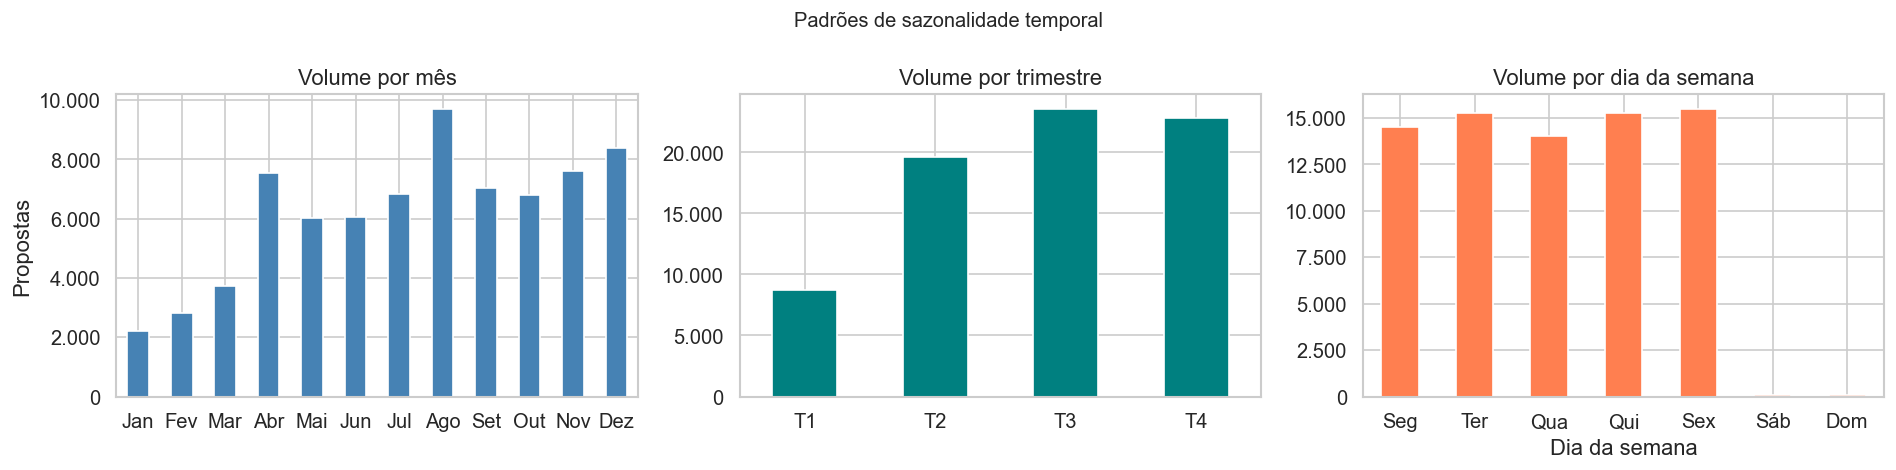

In [14]:
nomes_mes = ['Jan','Fev','Mar','Abr','Mai','Jun','Jul','Ago','Set','Out','Nov','Dez']

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

por_mes = df.groupby('mes').size()
por_mes.index = [nomes_mes[m-1] for m in por_mes.index]
por_mes.plot(kind='bar', ax=axes[0], color='steelblue', rot=0)
axes[0].set_title('Volume por mês')
axes[0].set_ylabel('Propostas')
fmt_eixo(axes[0], 'y', 0)

por_tri = df.groupby('trimestre').size()
por_tri.index = ['T' + str(i) for i in por_tri.index]
por_tri.plot(kind='bar', ax=axes[1], color='teal', rot=0)
axes[1].set_title('Volume por trimestre')
fmt_eixo(axes[1], 'y', 0)

por_dia = df.groupby('dia_semana').size()
dias_nomes = {0:'Seg',1:'Ter',2:'Qua',3:'Qui',4:'Sex',5:'Sáb',6:'Dom'}
por_dia.index = por_dia.index.map(dias_nomes)
por_dia.plot(kind='bar', ax=axes[2], color='coral', rot=0)
axes[2].set_title('Volume por dia da semana')
axes[2].set_xlabel('Dia da semana')
fmt_eixo(axes[2], 'y', 0)

plt.suptitle('Padrões de sazonalidade temporal', fontsize=12)
plt.tight_layout()
plt.savefig('figuras_tcc/image8.png', dpi=200, bbox_inches='tight')
plt.show()

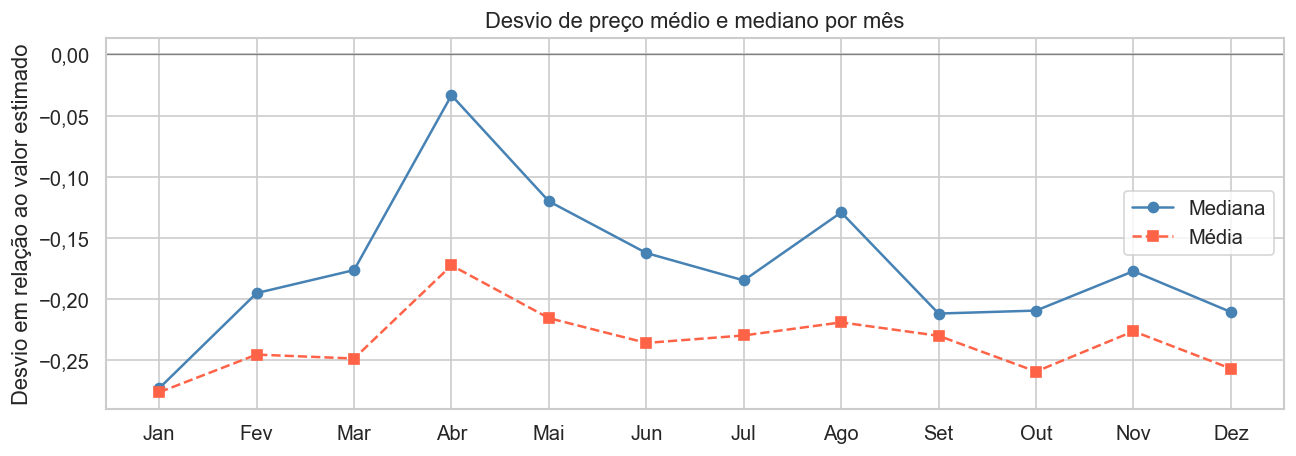

       mean  median     std
Jan -0.2760 -0.2727  0.2393
Fev -0.2452 -0.1950  0.2435
Mar -0.2484 -0.1762  0.2540
Abr -0.1723 -0.0334  0.2598
Mai -0.2154 -0.1200  0.2462
Jun -0.2357 -0.1622  0.2651
Jul -0.2296 -0.1846  0.2593
Ago -0.2189 -0.1291  0.2402
Set -0.2299 -0.2117  1.5610
Out -0.2591 -0.2093  0.2512
Nov -0.2262 -0.1771  0.2966
Dez -0.2567 -0.2105  0.2483


In [15]:
# Desvio de preço médio por mês
desvio_por_mes = df.groupby('mes')['desvio_item_estimado'].agg(['mean','median','std'])
desvio_por_mes.index = [nomes_mes[m-1] for m in desvio_por_mes.index]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(desvio_por_mes.index, desvio_por_mes['median'], marker='o', color='steelblue', label='Mediana')
ax.plot(desvio_por_mes.index, desvio_por_mes['mean'], marker='s', color='tomato',
        linestyle='--', label='Média')
ax.axhline(0, color='gray', linewidth=0.8)
ax.set_title('Desvio de preço médio e mediano por mês')
ax.set_ylabel('Desvio em relação ao valor estimado')
ax.legend()
fmt_eixo(ax, 'y', 2)
plt.tight_layout()
plt.savefig('figuras_tcc/image18.png', dpi=200, bbox_inches='tight')
plt.show()

print(desvio_por_mes.round(4).to_string())

---
### 7. Análise Eleitoral

Referência: eleição municipal de **06/10/2024** (1º turno), data de **publicação** da contratação. A eleição de 2020 não se aplica (a base cobre 2023–2024).

- **`dias_desde_eleicao`**: distância em dias com sinal — negativa antes da eleição, positiva depois (−641 a +85).
- **`pre_eleitoral_180d`**: 1 se publicada nos 180 dias imediatamente anteriores (−180 a −1) — 40,3% da base.
- **`pos_eleitoral_180d`**: 1 se publicada nos 180 dias seguintes (0 a +180) — 19,2% da base (a base termina 85 dias após a eleição).
- `ano_eleitoral` foi retirada: é idêntica a `ano == 2024`.

**Cuidados na leitura:** a janela anterior cai inteira entre abril e outubro de 2024, então ela se confunde com o ano e o mês; por isso os testes
abaixo também comparam a janela com o restante **de 2024**. Além disso, 75,9% dos registros são de órgãos federais, para os quais a eleição municipal
tem pertinência limitada, e o 2º turno (27/10/2024) não é considerado.

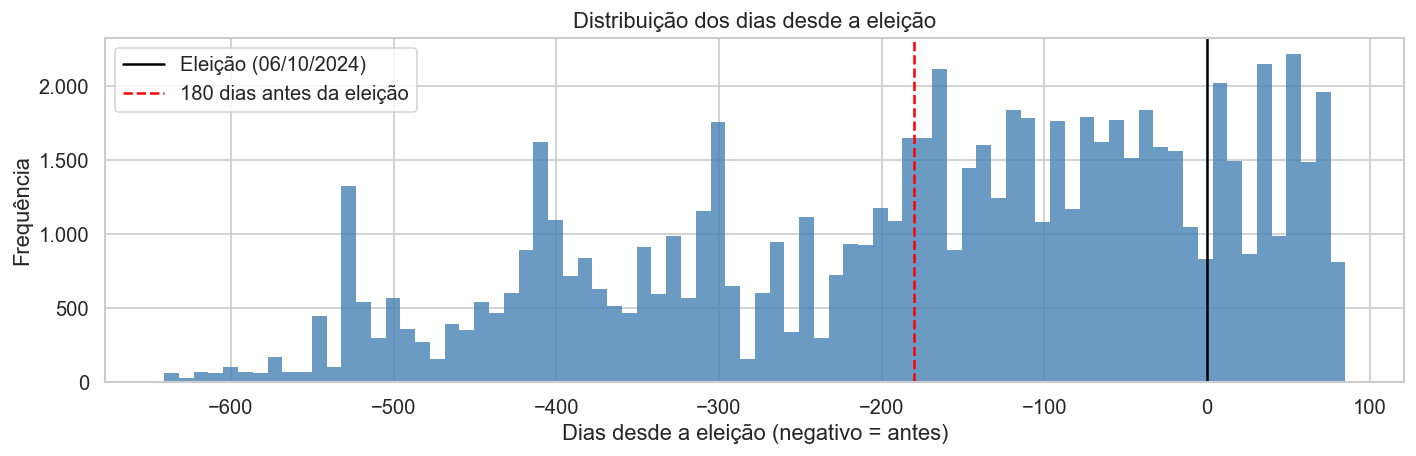

In [16]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.hist(df['dias_desde_eleicao'], bins=80, color='steelblue', alpha=0.8, edgecolor='none')
ax.axvline(0, color='black', linestyle='-', label='Eleição (06/10/2024)')
ax.axvline(-180, color='red', linestyle='--', label='180 dias antes da eleição')
ax.set_title('Distribuição dos dias desde a eleição')
ax.set_xlabel('Dias desde a eleição (negativo = antes)')
ax.set_ylabel('Frequência')
ax.legend()
fmt_eixo(ax, 'x', 0)
fmt_eixo(ax, 'y', 0)
plt.tight_layout()
plt.savefig('figuras_tcc/image7.png', dpi=200, bbox_inches='tight')
plt.show()


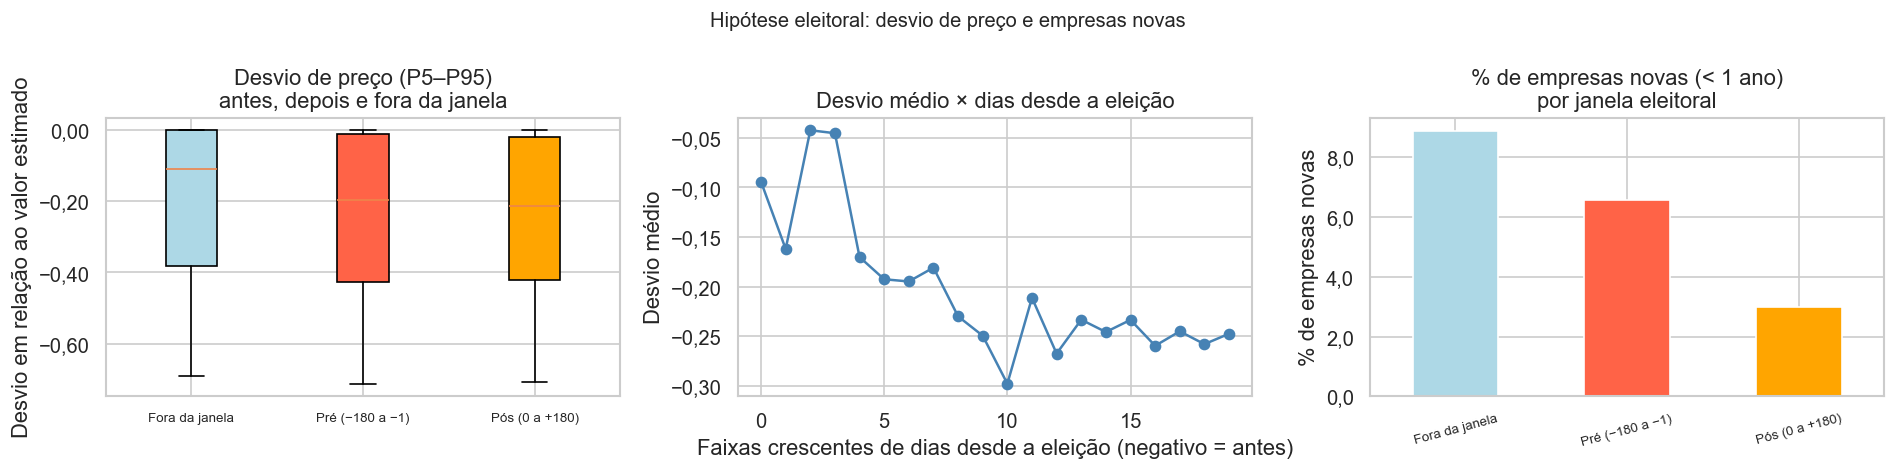

Mann-Whitney U (desvio de preço): grupo 1 × grupo 0
                                n grupo 1  n grupo 0  mediana grupo 1  mediana grupo 0  % > +50% grupo 1  % > +50% grupo 0  p-valor  efeito (rank-biserial)
pré × resto                       30091.0    44664.0          -0.1951          -0.1488            0.0299            0.0784  6.2e-77                 -0.0793
pós × resto                       14380.0    60375.0          -0.2120          -0.1540            0.1460            0.0381  8.8e-65                 -0.0903
pré × pós                         30091.0    14380.0          -0.1951          -0.2120            0.0299            0.1460  2.1e-05                  0.0248
pré × fora da janela (só 2024)    30091.0     9482.0          -0.1951          -0.1989            0.0299            0.0316  4.4e-01                  0.0052
2024 × 2023                       53953.0    20802.0          -0.2000          -0.0563            0.0612            0.0529  0.0e+00                 -0.1976


In [17]:
grupo = np.select([df['pre_eleitoral_180d'] == 1, df['pos_eleitoral_180d'] == 1],
                  ['Pré (−180 a −1)', 'Pós (0 a +180)'], default='Fora da janela')
ordem = ['Fora da janela', 'Pré (−180 a −1)', 'Pós (0 a +180)']
cores = ['lightblue', 'tomato', 'orange']

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Boxplot do desvio por janela eleitoral
data_box = [df.loc[grupo == g, 'desvio_item_estimado'] for g in ordem]
bp = axes[0].boxplot(data_box, labels=ordem, whis=[5, 95], showfliers=False, patch_artist=True)
for patch, color in zip(bp['boxes'], cores):
    patch.set_facecolor(color)
plt.setp(axes[0].get_xticklabels(), fontsize=8)
axes[0].set_title('Desvio de preço (P5–P95)\nantes, depois e fora da janela')
axes[0].set_ylabel('Desvio em relação ao valor estimado')
fmt_eixo(axes[0], 'y', 2)

# Desvio médio em faixas de dias_desde_eleicao
df['dias_bin'] = pd.cut(df['dias_desde_eleicao'], bins=20)
desvio_por_dias = df.groupby('dias_bin', observed=True)['desvio_item_estimado'].mean()
axes[1].plot(range(len(desvio_por_dias)), desvio_por_dias.values,
             marker='o', color='steelblue', linewidth=1.5)
axes[1].set_title('Desvio médio × dias desde a eleição')
axes[1].set_xlabel('Faixas crescentes de dias desde a eleição (negativo = antes)')
axes[1].set_ylabel('Desvio médio')
fmt_eixo(axes[1], 'x', 0)
fmt_eixo(axes[1], 'y', 2)

# Taxa de empresa nova por janela
taxa_nova_eleit = df.groupby(grupo)['empresa_nova'].mean().reindex(ordem) * 100
taxa_nova_eleit.plot(kind='bar', ax=axes[2], color=cores, rot=15)
axes[2].set_title('% de empresas novas (< 1 ano)\npor janela eleitoral')
axes[2].set_ylabel('% de empresas novas')
plt.setp(axes[2].get_xticklabels(), fontsize=8)
fmt_eixo(axes[2], 'y', 1)

plt.suptitle('Hipótese eleitoral: desvio de preço e empresas novas', fontsize=12)
plt.tight_layout()
plt.savefig('figuras_tcc/image12.png', dpi=200, bbox_inches='tight')
plt.show()

# Testes de Mann-Whitney sobre o desvio de preço. Efeito = correlação rank-biserial
# (positivo: o grupo 1 tende a ter desvio maior). Com n > 70 mil o p-valor é pequeno para qualquer diferença;
# o tamanho de efeito e a comparação dentro de 2024 (que controla o ano) é que informam.
def mann_whitney(g1, g0):
    a, b = df.loc[g1, 'desvio_item_estimado'], df.loc[g0, 'desvio_item_estimado']
    u, p = stats.mannwhitneyu(a, b, alternative='two-sided')
    return {'n grupo 1': len(a), 'n grupo 0': len(b),
            'mediana grupo 1': a.median(), 'mediana grupo 0': b.median(),
            '% > +50% grupo 1': (a > 0.5).mean() * 100, '% > +50% grupo 0': (b > 0.5).mean() * 100,
            'p-valor': p, 'efeito (rank-biserial)': 2 * u / (len(a) * len(b)) - 1}

pre, pos = df['pre_eleitoral_180d'] == 1, df['pos_eleitoral_180d'] == 1
fora_2024 = (df['ano'] == 2024) & ~pre & ~pos
testes = pd.DataFrame({
    'pré × resto': mann_whitney(pre, ~pre),
    'pós × resto': mann_whitney(pos, ~pos),
    'pré × pós': mann_whitney(pre, pos),
    'pré × fora da janela (só 2024)': mann_whitney(pre, fora_2024),
    '2024 × 2023': mann_whitney(df['ano'] == 2024, df['ano'] == 2023),
}).T
pval_u = testes.loc['pré × fora da janela (só 2024)', 'p-valor']
efeito_u = testes.loc['pré × fora da janela (só 2024)', 'efeito (rank-biserial)']

print('Mann-Whitney U (desvio de preço): grupo 1 × grupo 0')
exibe = testes.copy()
exibe['p-valor'] = exibe['p-valor'].map(lambda v: f'{v:.1e}')
print(exibe.round(4).to_string())


---
### 8. Análise Geográfica

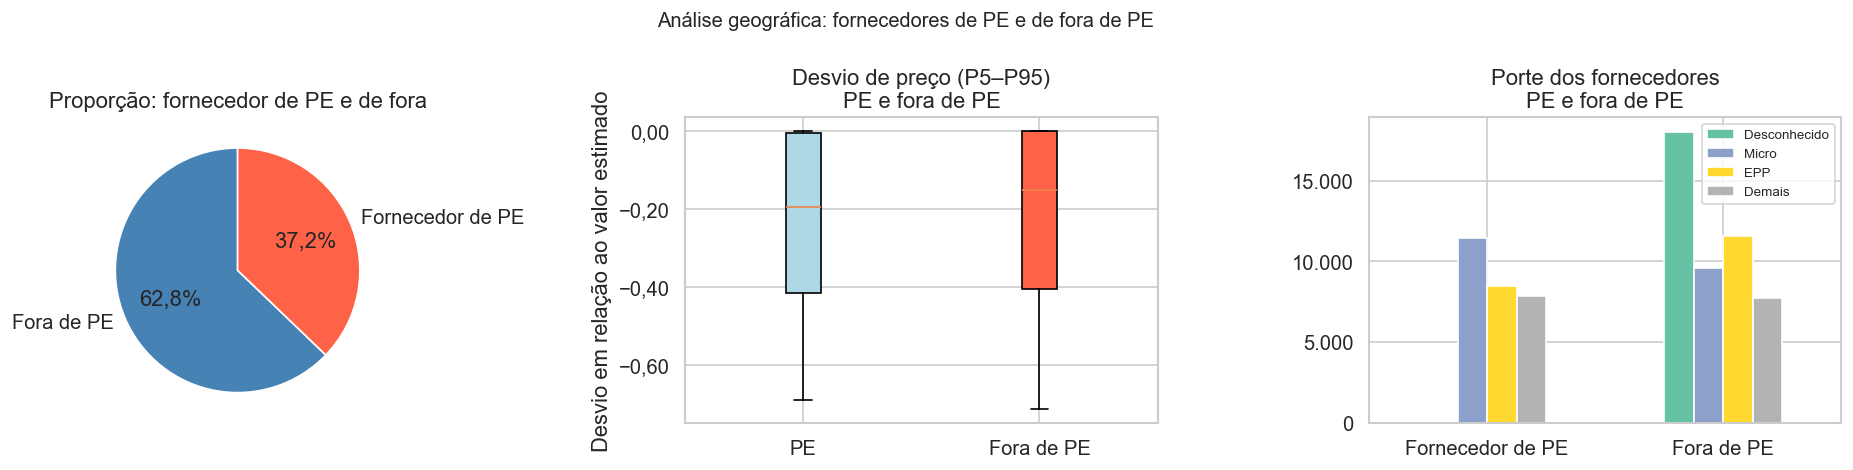

Mediana desvio PE:      -0.1928
Mediana desvio Fora PE: -0.1502
Mann-Whitney p-value:   0.0000


In [18]:
fora_pe_labels = {0: 'Fornecedor de PE', 1: 'Fora de PE'}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

fora_pe_counts = df['fornecedor_fora_pe'].value_counts()
axes[0].pie(fora_pe_counts.values,
            labels=[fora_pe_labels[k] for k in fora_pe_counts.index],
            autopct=lambda p: br(p, 1) + '%', colors=['steelblue', 'tomato'], startangle=90)
axes[0].set_title('Proporção: fornecedor de PE e de fora')

g_pe   = df.loc[df['fornecedor_fora_pe'] == 0, 'desvio_item_estimado']
g_fora = df.loc[df['fornecedor_fora_pe'] == 1, 'desvio_item_estimado']
bp = axes[1].boxplot([g_pe, g_fora], labels=['PE', 'Fora de PE'],
                     whis=[5,95], showfliers=False, patch_artist=True)
for patch, c in zip(bp['boxes'], ['lightblue', 'tomato']):
    patch.set_facecolor(c)
axes[1].set_title('Desvio de preço (P5–P95)\nPE e fora de PE')
axes[1].set_ylabel('Desvio em relação ao valor estimado')
fmt_eixo(axes[1], 'y', 2)

porte_map2 = {0: 'Desconhecido', 1: 'Micro', 2: 'EPP', 3: 'Demais'}
porte_geo = df.groupby(['fornecedor_fora_pe', 'porte']).size().unstack(fill_value=0)
porte_geo.index = [fora_pe_labels[k] for k in porte_geo.index]
porte_geo.columns = [porte_map2.get(c, str(c)) for c in porte_geo.columns]
porte_geo.plot(kind='bar', ax=axes[2], rot=0, colormap='Set2')
axes[2].set_title('Porte dos fornecedores\nPE e fora de PE')
axes[2].legend(fontsize=8)
fmt_eixo(axes[2], 'y', 0)

plt.suptitle('Análise geográfica: fornecedores de PE e de fora de PE', fontsize=12)
plt.tight_layout()
plt.savefig('figuras_tcc/image17.png', dpi=200, bbox_inches='tight')
plt.show()

print(f'Mediana desvio PE:      {g_pe.median():.4f}')
print(f'Mediana desvio Fora PE: {g_fora.median():.4f}')
stat_geo, pval_geo = stats.mannwhitneyu(g_pe, g_fora, alternative='two-sided')
print(f'Mann-Whitney p-value:   {pval_geo:.4f}')

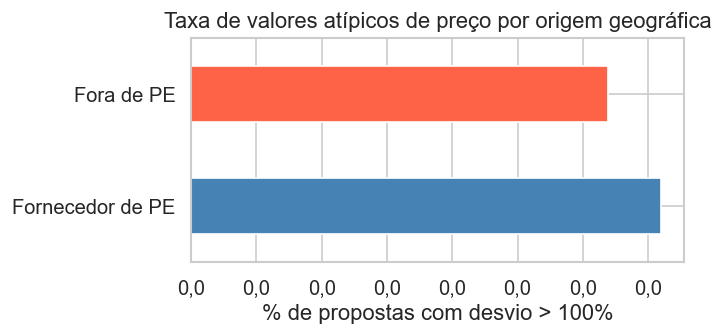

In [19]:
taxa_outlier_geo = df.groupby('fornecedor_fora_pe')['outlier_preco'].mean() * 100
taxa_outlier_geo.index = [fora_pe_labels[k] for k in taxa_outlier_geo.index]

fig, ax = plt.subplots(figsize=(6, 3))
taxa_outlier_geo.plot(kind='barh', ax=ax, color=['steelblue', 'tomato'])
ax.set_xlabel('% de propostas com desvio > 100%')
ax.set_title('Taxa de valores atípicos de preço por origem geográfica')
fmt_eixo(ax, 'x', 1)
plt.tight_layout()
plt.show()

---
### 9. Análise por Modalidade Licitatória

A modalidade licitatória determina o rito processual e o nível de competição esperado.

1. **Volume por modalidade**: quais modalidades concentram mais propostas?
2. **Desvio de preço por modalidade**: modalidades com menos concorrência tendem a ter
   maior sobrepreço?
3. **Fornecedor único por modalidade**: a taxa de `fornecedor_unico` varia por modalidade?
   Modalidades de Dispensa e Inexigibilidade têm naturalmente alta taxa, mas em Pregão
   Eletrônico é um sinal de alerta.
4. **Heatmap de risco**: visualização cruzada de 5 indicadores de risco por modalidade,
   normalizada por coluna para comparação relativa entre modalidades.

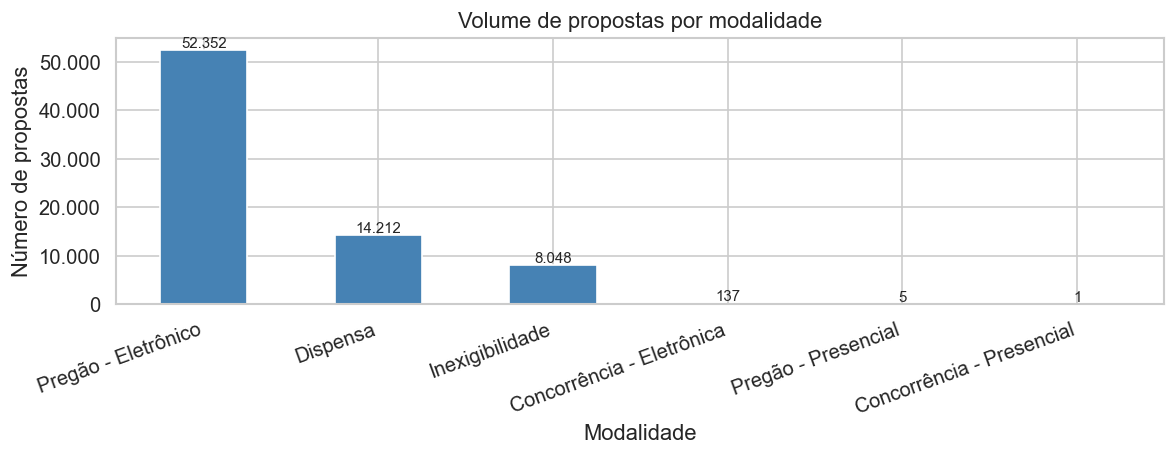

In [20]:
modal_counts = df['modalidadeNome'].value_counts().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 4))
modal_counts.plot(kind='bar', ax=ax, color='steelblue', rot=20)
plt.setp(ax.get_xticklabels(), ha='right')
ax.set_title('Volume de propostas por modalidade')
ax.set_xlabel('Modalidade')
ax.set_ylabel('Número de propostas')
fmt_eixo(ax, 'y', 0)
for p in ax.patches:
    ax.annotate(br(p.get_height(), 0),
                (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.savefig('figuras_tcc/image1.png', dpi=200, bbox_inches='tight')
plt.show()

In [21]:
modal_stats = df.groupby('modalidadeNome').agg(
    n_propostas=('desvio_item_estimado', 'count'),
    desvio_mediana=('desvio_item_estimado', 'median'),
    desvio_media=('desvio_item_estimado', 'mean'),
    taxa_outlier=('outlier_preco', 'mean'),
    taxa_forn_unico=('fornecedor_unico', 'mean'),
    taxa_empresa_nova=('empresa_nova', 'mean'),
    taxa_fora_pe=('fornecedor_fora_pe', 'mean')
).sort_values('n_propostas', ascending=False)

modal_stats[['taxa_outlier','taxa_forn_unico','taxa_empresa_nova','taxa_fora_pe']] *= 100

print('Estatisticas por Modalidade:')
modal_stats.round(3)

Estatisticas por Modalidade:


,n_propostas,desvio_mediana,desvio_media,taxa_outlier,taxa_forn_unico,taxa_empresa_nova,taxa_fora_pe
modalidadeNome,,,,,,,
Pregão - Eletrônico,52352,-0.267,-0.295,0.040,94.277,6.493,60.926
Dispensa,14212,-0.008,-0.110,0.028,84.337,11.589,53.511
Inexigibilidade,8048,0.000,-0.023,0.000,87.189,0.522,91.936
Concorrência - Eletrônica,137,-0.174,-0.178,0.000,78.832,0.730,42.336
Pregão - Presencial,5,-0.055,-0.114,0.000,100.000,0.000,100.000
Concorrência - Presencial,1,0.000,0.000,0.000,100.000,0.000,100.000


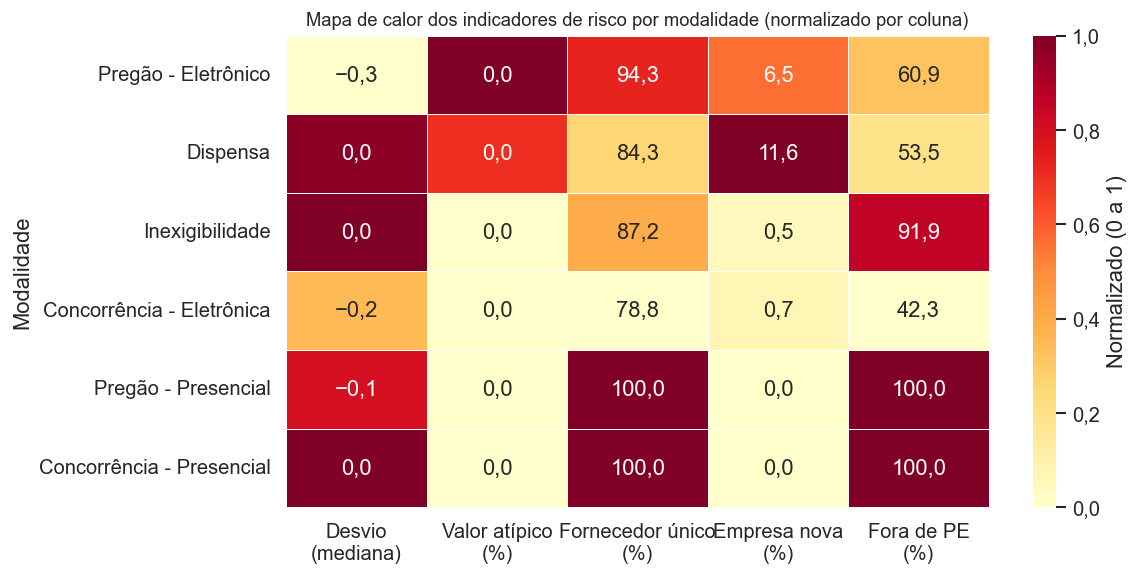

In [22]:
risk_cols   = ['desvio_mediana','taxa_outlier','taxa_forn_unico','taxa_empresa_nova','taxa_fora_pe']
risk_labels = ['Desvio\n(mediana)','Valor atípico\n(%)','Fornecedor único\n(%)','Empresa nova\n(%)','Fora de PE\n(%)']

risk_df   = modal_stats[risk_cols].copy()
risk_norm = (risk_df - risk_df.min()) / (risk_df.max() - risk_df.min() + 1e-9)
rot = risk_df.round(1).map(lambda v: br(v, 1))

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(risk_norm, annot=rot, fmt='',
            cmap='YlOrRd', ax=ax, xticklabels=risk_labels,
            linewidths=0.5, cbar_kws={'label': 'Normalizado (0 a 1)'})
fmt_eixo(ax.collections[0].colorbar.ax, 'y', 1)
ax.set_xlabel('')
ax.set_ylabel('Modalidade')
ax.set_title('Mapa de calor dos indicadores de risco por modalidade (normalizado por coluna)', fontsize=11)
plt.tight_layout()
plt.show()

---
### 10. Síntese dos Achados da EDA

In [23]:
print('=' * 65)
print('SINTESE DA EDA - NB07')
print('=' * 65)

print('\n--- Dataset ---')
print(f'Total de propostas:             {len(df):>10,}')
n_orgaos = df['orgaoEntidadeCnpj'].nunique()
n_forn   = df['cnpj_forn_norm'].nunique()
print(f'Orgaos compradores:             {n_orgaos:>10,}')
print(f'Fornecedores unicos:            {n_forn:>10,}')
print(f'Periodo coberto:                2023 - 2024')

print('\n--- Preco ---')
med_glob  = df['desvio_item_estimado'].median()
mean_glob = df['desvio_item_estimado'].mean()
pct_50  = (df['desvio_item_estimado'] > 0.5).mean() * 100
pct_100 = (df['desvio_item_estimado'] > 1.0).mean() * 100
print(f'Desvio mediano global:          {med_glob:>10.4f}')
print(f'Desvio medio global:            {mean_glob:>10.4f}')
print(f'Propostas com desvio > 50%:     {pct_50:>9.1f}%')
print(f'Propostas com desvio > 100%:    {pct_100:>9.1f}%')

print('\n--- Eleitoral ---')
print(f'Propostas 180d antes da eleicao:  {df["pre_eleitoral_180d"].mean()*100:>9.1f}%')
print(f'Propostas 180d depois da eleicao: {df["pos_eleitoral_180d"].mean()*100:>9.1f}%')
print(f'Desvio mediano pre x resto:       {testes.loc["pré × resto","mediana grupo 1"]:>8.4f} x {testes.loc["pré × resto","mediana grupo 0"]:.4f}')
print(f'Pre x fora da janela (so 2024):   p = {pval_u:.4f} | efeito = {efeito_u:+.3f}')

print('\n--- Geografico ---')
pct_fora_pe = df['fornecedor_fora_pe'].mean() * 100
print(f'Fornecedores fora de PE:        {pct_fora_pe:>9.1f}%')
print(f'Desvio mediano forn. PE:        {g_pe.median():>10.4f}')
print(f'Desvio mediano forn. fora PE:   {g_fora.median():>10.4f}')
print(f'p-value Mann-Whitney:           {pval_geo:>10.4f}')

print('\n--- Perfil de Fornecedores ---')
pct_unico  = df['fornecedor_unico'].mean() * 100
pct_fisica = (df['tipo_fornecedor']==0).mean() * 100
pct_nova   = df['empresa_nova'].mean() * 100
pct_micro  = (df['porte']==1).mean() * 100
print(f'Fornecedor unico (item):        {pct_unico:>9.1f}%')
print(f'Pessoas fisicas:                {pct_fisica:>9.1f}%')
print(f'Empresas novas (<1 ano):        {pct_nova:>9.1f}%')
print(f'Micro empresas (porte=1):       {pct_micro:>9.1f}%')

print('\n' + '=' * 65)

SINTESE DA EDA - NB07

--- Dataset ---
Total de propostas:                 74,755
Orgaos compradores:                    103
Fornecedores unicos:                 9,437
Periodo coberto:                2023 - 2024

--- Preco ---
Desvio mediano global:             -0.1667
Desvio medio global:               -0.2301
Propostas com desvio > 50%:           0.1%
Propostas com desvio > 100%:          0.0%

--- Eleitoral ---
Propostas 180d antes da eleicao:       40.3%
Propostas 180d depois da eleicao:      19.2%
Desvio mediano pre x resto:        -0.1951 x -0.1488
Pre x fora da janela (so 2024):   p = 0.4381 | efeito = +0.005

--- Geografico ---
Fornecedores fora de PE:             62.8%
Desvio mediano forn. PE:           -0.1928
Desvio mediano forn. fora PE:      -0.1502
p-value Mann-Whitney:               0.0000

--- Perfil de Fornecedores ---
Fornecedor unico (item):             91.6%
Pessoas fisicas:                      8.1%
Empresas novas (<1 ano):              6.8%
Micro empresas (porte=1

In [24]:
features_modelo = [
    # Preço
    'desvio_item_estimado',
    # Concorrência
    'n_propostas_item', 'fornecedor_unico',
    # Temporal
    'ano', 'mes', 'trimestre', 'dia_semana',
    # Eleitoral
    'dias_desde_eleicao', 'pre_eleitoral_180d', 'pos_eleitoral_180d',
    # Geográfica
    'fornecedor_fora_pe',
    # Empresa
    'tipo_fornecedor', 'idade_empresa_anos', 'empresa_nova',
    'opcao_pelo_mei', 'opcao_pelo_simples',
    'modalidade_Dispensa', 'modalidade_Inexigibilidade', 'modalidade_Licitacao', 'porte',
    'descricao_situacao_cadastral',
]
# cnae_fiscal fica de fora dos modelos: como número, domina a distância (LOF) e cria
# vizinhança sem sentido; a ausência de cadastro já é sinalizada por porte == 0.
# A coluna segue em dataset_ml_clean.csv (descritiva). A modalidade entra como one-hot (modalidade_*).

ausentes = [f for f in features_modelo if f not in df.columns]
if ausentes:
    print(f'AVISO: features ausentes no dataset: {ausentes}')
else:
    print(f'OK - {len(features_modelo)} features de modelagem verificadas.')

shape_modelo = df[features_modelo].shape
print(f'\nShape do subset de modelagem: {shape_modelo}')

# Identificadores para rastreabilidade no NB08 (mapear scores de volta às propostas)
identificadores = ['orgaoEntidadeCnpj', 'anoCompraPncp', 'sequencialCompraPncp',
                   'numeroItem', 'cnpj_forn_norm']

import os
os.makedirs('data/load', exist_ok=True)

output_path = 'data/load/dataset_ml_model.csv'
df[identificadores + features_modelo].to_csv(output_path, index=False)
print(f'\nSalvo em {output_path}: {df[identificadores + features_modelo].shape}')

OK - 21 features de modelagem verificadas.

Shape do subset de modelagem: (74755, 21)



Salvo em data/load/dataset_ml_model.csv: (74755, 26)
